Basic ML (1 real input and 1 real output) - Polinomial regression + Regularization

In [31]:
import numpy as np # numerical things
import numpy.matlib as nml # matricial computations
import matplotlib.pyplot as plt # plots

In [32]:
# Change of seed
np.random.seed(15)

In [33]:
# I change my oracle (the function I want to learn form the data)
def oracle(x):
  #return x**2
  return np.abs(np.abs(x-.4)-.2) + x/2-.1

In [34]:
n = 8
sigma = 0
nt = 1000

In [35]:
x = np.random.rand(n)
y = oracle(x) + sigma * np.random.randn(n)
xt = np.linspace(0,1,nt)
yt = oracle(xt)

'Model of the new oracle'

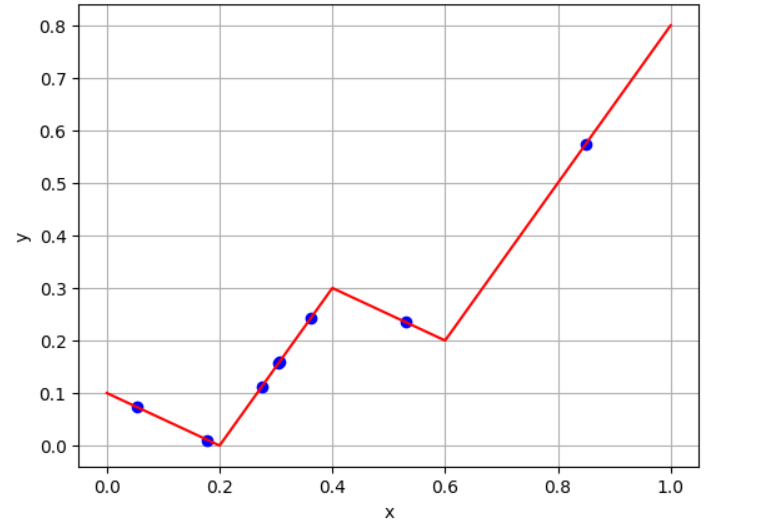

In [36]:
from IPython.display import Image, display
display("Model of the new oracle", Image(filename="/content/modelneworacle.png", width=450))

In [37]:
x = np.asmatrix(x).transpose()
y = np.asmatrix(y).transpose()
xt = np.asmatrix(xt).transpose()
yt = np.asmatrix(yt).transpose()

In [38]:
# | X c - y | ^2 + lam c' M c
# I change the matrix M wrt to before

lam = 10**(-6)
for p in range(0,14):

  M = nml.zeros((p+1, p+1))

  for i in range(2, p+1):
    for j in range(2, p+1):
      M[i,j] = i * (i-1) * j * (j-1) / (i+j-3)

  X = nml.ones((n,1))
  Xt = nml.ones((nt,1))

  for i in range (1, p+1):
    X = np.concatenate((X,np.power(x,i)), axis=1)
    Xt = np.concatenate((Xt,np.power(xt,i)), axis=1)

  c = np.linalg.solve(X.T*X+lam*M, X.T*y)
  yp = np.matmul(Xt,c)
  err = np.mean(np.power(yt-yp,2))
  print(str(p), '\t', str(err))

0 	 0.056328081590035474
1 	 0.006486683640134496
2 	 0.003640214224827649
3 	 0.0034474016684916567
4 	 0.08733001663117
5 	 0.01753903590545423
6 	 0.047980367756898096
7 	 0.014504447701161697
8 	 0.009242898008384114
9 	 0.0012205784262665994
10 	 0.001226422603147691
11 	 0.0004103964567343568
12 	 0.00039672152167746647
13 	 0.0002873172148369769


The smallest error is when p is very big (p = 13). This model is complex enough to get better results.

If I use p too small it should not be ok (model too simple to fit the data); also a too high p could be a problem, because the model could be overfitting the system (taking into consideration also noise or corruption to the data -> not too easy to learn from the data).

In this case the best p is kinda big, because the model we are using is

|X c - y| + lam * c' M c

The fact that I am using a very complex p does not mean I am using a very complex model -> the term c' M c keeps my model simple.

I will get the same result changing lambda (if still very small).

-> This phenomena is called OVERPARAMETRIZATION! (different from OVERFITTING).
Overparametrization happens when I am using more parameters than the ones I actually need (ex: here I am using 8 points, but a polynome of degree 13).
Overfitting, I fit in the data, not the info in the data.

Overparametrization happens lots of time. It allows me to find better solution. The more function I put in my basket, the more probabile is that I find a function that fit better my system.

In ML I am minimizing the error on my data AND the semplicity of the solution -> p larger does not imply more complex models

p = 4  

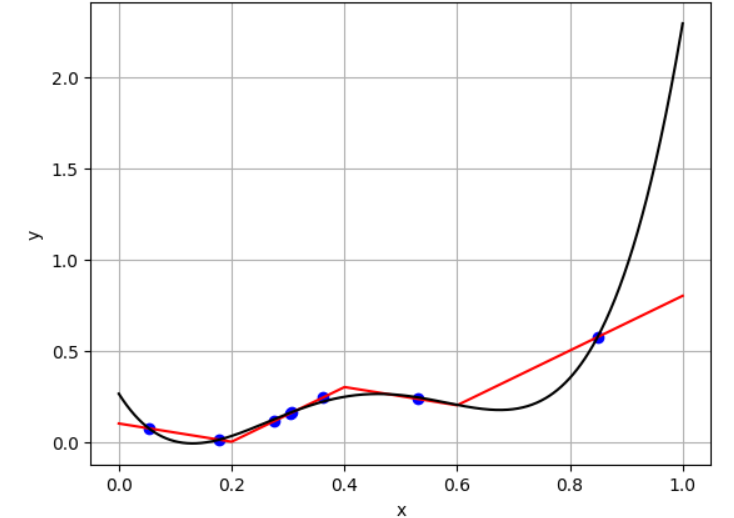

p = 13  

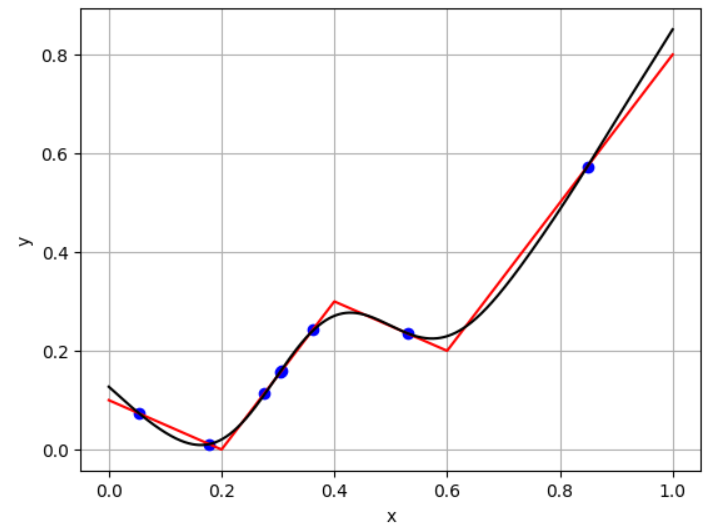

In [39]:

from IPython.display import Image, display

image_paths = [
    "/content/p4.png",
    "/content/p13.png"
]

p_arr = [4, 13]

for i, path in enumerate(image_paths):
    print(f"p =", p_arr[i], end="  ")
    display(Image(filename=path, width=200))

We can see that the model with p = 13 is much more simple than the one with only 4 parameters. Adding more parameters can help -> it's probable I will get a solution with small error and a simpler model (the number of oscillation is very small).